# Frequency probing: pure tones

## tl;dr

This notebook measures how efficiently seven frequency-band labels can be read
at ten stages of the network: the four encoder blocks, the four decoder blocks,
the input of the output projection and the output quantile head. Every value is
accompanied by a shuffled-label control and by the same reading on an untrained
network. A lock/control reading then compares, stage by stage, how often a tone
on a candidate site and a tone beside it are located. It produces the retrained
16–16 SV figure and the tables for Appendix F. Run from top to bottom to populate
the results; the tables and figures below come from the returned, validated
measurements.

## Context & Methods

Frozen Chronos-Bolt-Tiny checkpoints are read at ten probe points: the [REG]
vector after each of the four encoder blocks (its last position) and after each
of the four decoder blocks (the single query token), the input of the output
projection, and its output, the quantile head. The seven hierarchical binary
frequency tasks are ordered by decision threshold: LL, L, LH, Mid, HL, H and HH.
We retain their existing bands and boundaries.

**Description length by stage.** For each task, unique frequencies are assigned
to five class-stratified prequential blocks. All phases at a frequency remain in
the same block. The first block is charged uniformly at one bit per label; every
later block is encoded by a linear probe trained only on preceding blocks. The
scaler and PCA (up to 20 components) are fitted inside that preceding-data fit,
followed by logistic regression. A fixed seed of 42 governs splits, probe
randomness and both controls. The reported space saving is
\[
SV = 1 - \frac{L_{\mathrm{MDL}}}{n}.
\]
Positive SV means label compression, zero means no saving, and negative values
are retained. The initial uniform block sets a design-dependent upper bound
near 0.8. SV measures the readability of frequency labels from these
representations; it does not measure compression of waveform samples.

**Two controls.** *Shuffled labels*: the same blocks and probe on permuted
labels. *Untrained network*: the same architecture with randomly initialised
weights reads the same contexts and is scored in the same way. What the
untrained network already exposes comes from the tokenisation and the
architecture; only the gap between the two networks can be attributed to training.

**Lock/control reading.** This mirrors the recovery count of the frequency
analysis, read inside the network instead of on the forecast. A tone on a
candidate site (lock) and a tone beside it (control, more than 2 Hz from every
candidate of the geometry) are presented at every phase. A tone is *located* at
a stage when the three band probes on its path (Mid, then L or H, then one of
LL, LH, HL, HH) all return its label, which places it in an eighth of the band.
The probes are fitted on the sweep without the frequencies within 1 Hz of the
lock or control tones, so no located tone was seen in fitting. The outcome is
the located rate at lock and control and their difference, stage by stage. Task
boundaries lie beside several candidate sites, so the reading is repeated on the
pairs whose tones all lie at least 4 Hz from the boundaries on their path.

### Key assumptions

- Signals are sampled at 512 Hz. The full grid is 2–250 Hz in 1-Hz steps,
  with ten explicitly distinct phases per frequency. Candidate sites keep
  their exact, possibly non-integer, value in the lock/control reading.
- Context length is the largest \(L\le512\) satisfying \(L\bmod P=0\) and
  \((L-P)\bmod S=0\), avoiding masked patch padding and uncovered samples.
- The published checkpoint and the fifteen retrained geometries use their
  existing, identified weights; no model is retrained here.
- The grouped five-block estimator is the repository's adapted protocol.
  The figure layout follows [Pagani et al., Figure 3](https://arxiv.org/html/2605.06361v1).
- These values are not those of `02_mdl_bandtasks.parquet` (Model B), whose
  blocks are not grouped by frequency.

### Set up the experiment

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

REPO = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "notebooks" / "support_scripts" / "probing_lib.py").is_file()),
    None,
)
if REPO is None:
    raise RuntimeError("Open this notebook from the patchAliasing repository.")
sys.path.insert(0, str(REPO / "notebooks" / "support_scripts"))

from probing_protocol import ProbeConfig, context_length, make_design
from probing_lib import MODELS

MODE = os.environ.get("PATCHALIASING_PROBING_MODE", "full").strip().lower()
if MODE not in {"full", "smoke"}:
    raise ValueError("PATCHALIASING_PROBING_MODE must be 'full' or 'smoke'.")
cfg = ProbeConfig.smoke() if MODE == "smoke" else ProbeConfig()
models = tuple(model for model in MODELS if model.tag == "retrained-p16-s16") if MODE == "smoke" else MODELS
ROOT = REPO / "notebooks" / "_run" / "probing"
DEVICE = "cpu"
TASK_ORDER = ["LL", "L", "LH", "Mid", "HL", "H", "HH"]
STAGE_ORDER = ["enc_0", "enc_1", "enc_2", "enc_3", "dec_0", "dec_1", "dec_2", "dec_3",
               "output_reg", "output_head"]
# Tracked copies of the values the report quotes (notebooks/_run is not in the repository).
PUBLISHED = REPO / "notebooks" / "signal_analysis" / "results" / "probing"

print(f"Mode: {MODE}; device: {DEVICE}; checkpoints: {len(models)}")
if MODE == "smoke":
    display(Markdown("**SMOKE CHECK — reduced design; these results are not report estimates.**"))

def lock_control_panel(summary, family, network="trained", suffix=""):
    """Geometry by stage: located rate at lock / at control, in per cent."""
    part = summary.loc[summary["family"].eq(family) & summary["network"].eq(network)].copy()
    part["cell"] = [("-" if pd.isna(l) or pd.isna(c) else f"{l:.0f}/{c:.0f}")
                    for l, c in zip(part[f"lock_pct{suffix}"], part[f"control_pct{suffix}"])]
    return part.pivot(index="model", columns="stage", values="cell").reindex(
        index=[model.tag for model in models], columns=STAGE_ORDER)


def net_panel(summary, family, network="trained", suffix=""):
    part = summary.loc[summary["family"].eq(family) & summary["network"].eq(network)]
    return part.pivot(index="model", columns="stage", values=f"net_pct{suffix}").reindex(
        index=[model.tag for model in models], columns=STAGE_ORDER).round(1)


def publish(paths):
    """Copy full-design exports next to the notebook so the report values are traceable."""
    import shutil
    if MODE != "full":
        return []
    PUBLISHED.mkdir(parents=True, exist_ok=True)
    copied = []
    for path in paths:
        shutil.copy2(path, PUBLISHED / path.name)
        copied.append(PUBLISHED / path.name)
    return copied

Mode: full; device: cpu; checkpoints: 16


## Data

Every example is an isolated unit-amplitude sinusoid. The ten full-design
phases are explicitly distinct over one cycle, replacing the legacy helper
that can repeat phases at some integer frequencies. All checkpoints receive
the same frequency/phase design, truncated only by their exact context rule.

In [2]:
design = make_design(cfg)
coverage = pd.DataFrame([
    {"model": model.tag, "P": model.P, "S": model.S,
     "context_samples": context_length(model.P, model.S)}
    for model in models
])
display(coverage)
print(f"{design['frequency'].nunique()} frequencies × {cfg.n_phases} phases = {len(design)} contexts per sweep")
display(design.head(6))

249 frequencies × 10 phases = 2490 contexts per sweep


,model,P,S,context_samples
0,official-p16-s16,16,16,512
1,retrained-p8-s8,8,8,512
2,retrained-p16-s8,16,8,512
3,retrained-p16-s12,16,12,496
4,retrained-p16-s16,16,16,512
5,retrained-p24-s8,24,8,504
6,retrained-p24-s12,24,12,504
7,retrained-p24-s16,24,16,504
8,retrained-p24-s20,24,20,504
9,retrained-p24-s24,24,24,504


,frequency,phase,phase_index
0,2.0,0.000000,0
1,2.0,0.628319,1
2,2.0,1.256637,2
3,2.0,1.884956,3
4,2.0,2.513274,4
5,2.0,3.141593,5


## Results

### Run or resume the sweep

The runner processes one checkpoint at a time, records checkpoint and package
identities, and reuses only shards matching the exact configuration, input
hashes and code. A failure stays visible; the notebook does not substitute
partial results. The full output has 16 × 10 × 7 = 1,120 task/stage rows, each
with its two controls, and one lock/control row per tone, stage and network.

In [3]:
from probing_lib import run_pure

results, run_dir = run_pure(ROOT, cfg=cfg, models=models, device=DEVICE)
trials = pd.read_csv(run_dir / "lock_control.csv")
prefix = "smoke_" if MODE == "smoke" else ""
lock_control = pd.read_csv(run_dir / f"{prefix}pure_lock_control.csv")
print(f"Validated SV rows: {len(results):,}; lock/control rows: {len(trials):,}")
print(f"Run directory: {run_dir}")

PURE full: 16 datasets; notebooks/_run/probing/pure/full/a8c6a2342aac701d
[1/16] official-p16-s16/pure/-1: computed (27.9s)
[2/16] retrained-p8-s8/pure/-1: computed (20.9s)
[3/16] retrained-p16-s8/pure/-1: computed (29.6s)
[4/16] retrained-p16-s12/pure/-1: computed (33.0s)
[5/16] retrained-p16-s16/pure/-1: computed (26.4s)
[6/16] retrained-p24-s8/pure/-1: computed (37.6s)
[7/16] retrained-p24-s12/pure/-1: computed (31.3s)
[8/16] retrained-p24-s16/pure/-1: computed (37.5s)
[9/16] retrained-p24-s20/pure/-1: computed (42.9s)
[10/16] retrained-p24-s24/pure/-1: computed (32.7s)
[11/16] retrained-p32-s8/pure/-1: computed (43.0s)
[12/16] retrained-p32-s12/pure/-1: computed (45.4s)
[13/16] retrained-p32-s16/pure/-1: computed (37.9s)
[14/16] retrained-p32-s20/pure/-1: computed (52.3s)
[15/16] retrained-p32-s24/pure/-1: computed (51.2s)
[16/16] retrained-p32-s32/pure/-1: computed (32.9s)
Validated SV rows: 1,120; lock/control rows: 12,720
Run directory: notebooks/_run/probing/pure/full/a8c6a2342

### Inspect the retrained 16–16

In [4]:
reference = results.loc[results["model"].eq("retrained-p16-s16")].copy()
if reference.empty:
    raise ValueError("The reference checkpoint is missing from the completed run.")
for column, name in (("SV", "trained network"), ("SV_shuffled", "shuffled-label control"),
                     ("SV_random_init", "untrained-network control")):
    display(reference.pivot(index="stage", columns="task", values=column)
            .reindex(index=STAGE_ORDER, columns=TASK_ORDER).round(3).rename_axis(name))

task,LL,L,LH,Mid,HL,H,HH
trained network,,,,,,,
enc_0,0.644,0.587,0.395,0.500,0.491,0.655,0.485
enc_1,0.597,0.465,0.541,0.506,0.421,0.630,0.470
enc_2,0.555,0.404,0.651,0.476,0.504,0.608,0.574
enc_3,0.515,0.449,0.585,0.486,0.514,0.551,0.463
dec_0,0.593,0.405,0.507,0.556,0.429,0.568,0.449
dec_1,0.656,0.466,0.621,0.565,0.188,0.582,0.439
dec_2,0.643,0.574,0.662,0.686,0.171,0.595,0.443
dec_3,0.617,0.337,0.703,0.602,0.250,0.572,0.317
output_reg,0.355,0.468,0.672,0.595,0.298,0.572,0.423


task,LL,L,LH,Mid,HL,H,HH
shuffled-label control,,,,,,,
enc_0,-0.033,-0.046,-0.067,-0.018,-0.130,-0.025,-0.078
enc_1,-0.042,-0.023,-0.079,-0.022,-0.166,-0.028,-0.024
enc_2,-0.036,-0.036,-0.049,-0.016,-0.117,-0.020,-0.055
enc_3,-0.047,-0.052,-0.047,-0.017,-0.087,-0.021,-0.041
dec_0,-0.208,-0.055,-0.150,-0.016,-0.156,-0.033,-0.045
dec_1,-0.194,-0.023,-0.116,-0.025,-0.208,-0.029,-0.044
dec_2,-0.160,-0.036,-0.125,-0.012,-0.193,-0.031,-0.056
dec_3,-0.074,-0.045,-0.098,-0.014,-0.135,-0.036,-0.040
output_reg,-0.074,-0.048,-0.093,-0.014,-0.153,-0.036,-0.042


task,LL,L,LH,Mid,HL,H,HH
untrained-network control,,,,,,,
enc_0,0.216,0.599,0.600,0.467,0.457,0.528,0.455
enc_1,0.170,0.592,0.598,0.477,0.449,0.521,0.420
enc_2,0.250,0.597,0.599,0.478,0.422,0.535,0.456
enc_3,0.209,0.595,0.600,0.484,0.420,0.533,0.471
dec_0,0.234,0.606,0.587,0.456,0.440,0.534,0.467
dec_1,0.279,0.610,0.598,0.470,0.424,0.529,0.470
dec_2,0.261,0.607,0.597,0.480,0.423,0.521,0.500
dec_3,0.193,0.612,0.599,0.475,0.424,0.522,0.480
output_reg,0.190,0.612,0.599,0.475,0.424,0.523,0.477


### Figure for Section 5.1

Seven bars within each stage show true-task SV; the parenthesised labels give
the shuffled-label and untrained-network controls. The zero line remains
visible and negative values are preserved. The image carries no title or note:
they belong to the caption. PNG and PDF exports share the same computed data.

notebooks/_run/probing/pure/full/a8c6a2342aac701d/fig_probing_sv_p16_s16.png


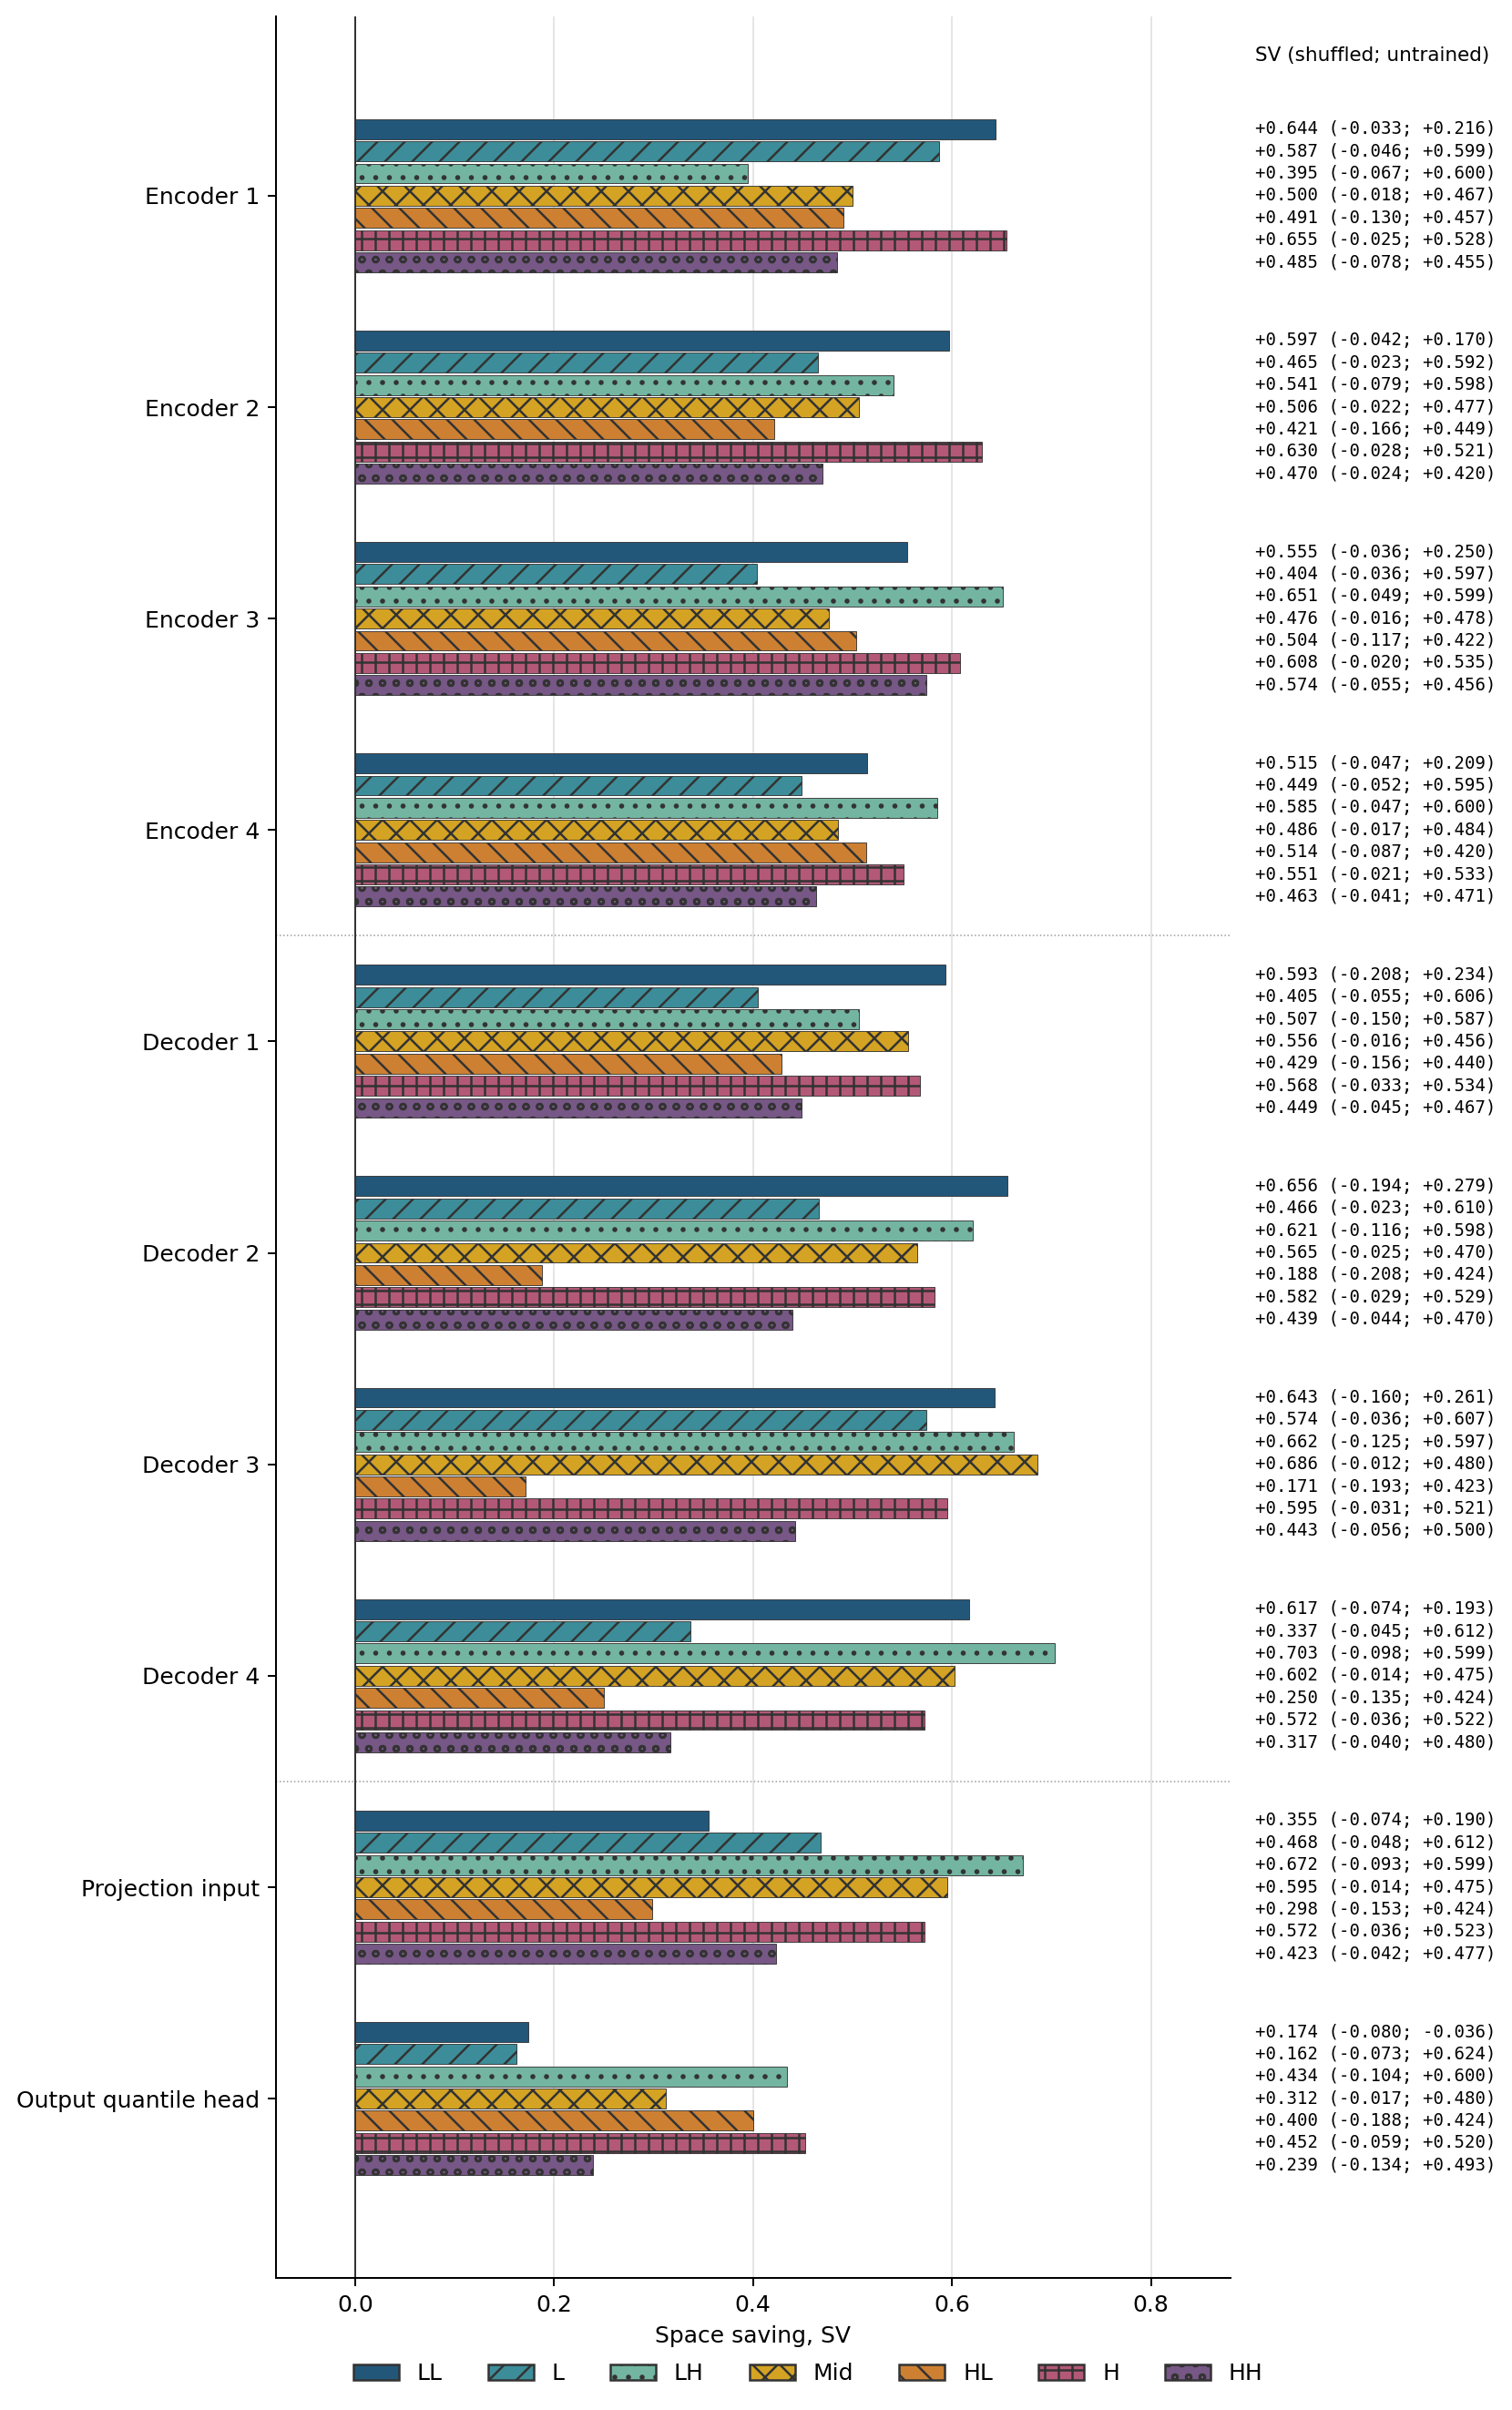

In [5]:
figure_paths = sorted(run_dir.glob(f"{prefix}fig_probing_sv_p16_s16.png"))
if len(figure_paths) != 1:
    raise RuntimeError(f"Expected one reference figure, found {len(figure_paths)}.")
display(Image(filename=str(figure_paths[0]), width=900))
print(figure_paths[0])

### All geometries, stage by stage

Median SV over the seven tasks at each stage, for the trained network and for
the untrained one. A trained value well above its untrained counterpart is
information the training added; comparable values are what the architecture
and the tokenisation already expose.

In [6]:
medians = results.groupby(["model", "stage"], sort=False)[["SV", "SV_random_init", "SV_shuffled"]].median()
order = [model.tag for model in models]
for column, name in (("SV", "trained network"), ("SV_random_init", "untrained network")):
    display(medians[column].unstack("stage").reindex(index=order, columns=STAGE_ORDER).round(2).rename_axis(name))
gap = (medians["SV"] - medians["SV_random_init"]).unstack("stage").reindex(index=order, columns=STAGE_ORDER)
display(gap.round(2).rename_axis("trained minus untrained"))
print(f"Shuffled-label control, largest median over all cells: {medians['SV_shuffled'].max():+.3f}")

Shuffled-label control, largest median over all cells: -0.028


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
trained network,,,,,,,,,,
official-p16-s16,0.75,0.74,0.75,0.75,0.74,0.76,0.70,0.70,0.70,0.37
retrained-p8-s8,0.70,0.70,0.70,0.68,0.67,0.70,0.68,0.63,0.65,0.45
retrained-p16-s8,0.64,0.61,0.68,0.67,0.54,0.57,0.56,0.58,0.53,0.26
retrained-p16-s12,0.60,0.63,0.54,0.57,0.55,0.65,0.64,0.60,0.59,0.37
retrained-p16-s16,0.50,0.51,0.55,0.51,0.51,0.56,0.60,0.57,0.47,0.31
retrained-p24-s8,0.59,0.61,0.56,0.51,0.49,0.54,0.49,0.52,0.52,0.23
retrained-p24-s12,0.54,0.51,0.51,0.51,0.58,0.63,0.65,0.62,0.60,0.28
retrained-p24-s16,0.37,0.35,0.39,0.40,0.55,0.61,0.65,0.58,0.54,0.33
retrained-p24-s20,0.54,0.49,0.51,0.54,0.59,0.52,0.62,0.58,0.56,0.28


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
untrained network,,,,,,,,,,
official-p16-s16,0.47,0.48,0.48,0.48,0.47,0.47,0.50,0.48,0.48,0.49
retrained-p8-s8,0.64,0.64,0.64,0.62,0.61,0.64,0.64,0.64,0.64,0.65
retrained-p16-s8,0.65,0.66,0.65,0.65,0.61,0.64,0.65,0.63,0.63,0.65
retrained-p16-s12,0.58,0.57,0.58,0.60,0.57,0.58,0.59,0.57,0.57,0.59
retrained-p16-s16,0.47,0.48,0.48,0.48,0.47,0.47,0.50,0.48,0.48,0.49
retrained-p24-s8,0.62,0.65,0.65,0.69,0.62,0.67,0.69,0.65,0.65,0.65
retrained-p24-s12,0.53,0.61,0.59,0.54,0.54,0.60,0.55,0.51,0.52,0.59
retrained-p24-s16,0.48,0.50,0.52,0.53,0.53,0.52,0.54,0.53,0.53,0.56
retrained-p24-s20,0.59,0.56,0.61,0.58,0.56,0.59,0.57,0.57,0.57,0.63


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
trained minus untrained,,,,,,,,,,
official-p16-s16,0.28,0.26,0.27,0.26,0.27,0.29,0.20,0.22,0.22,-0.12
retrained-p8-s8,0.06,0.06,0.06,0.06,0.05,0.05,0.03,-0.01,0.00,-0.19
retrained-p16-s8,-0.01,-0.05,0.03,0.03,-0.07,-0.08,-0.09,-0.06,-0.11,-0.39
retrained-p16-s12,0.01,0.06,-0.04,-0.04,-0.02,0.07,0.05,0.03,0.02,-0.22
retrained-p16-s16,0.03,0.03,0.08,0.03,0.04,0.10,0.10,0.09,-0.01,-0.18
retrained-p24-s8,-0.02,-0.04,-0.09,-0.17,-0.13,-0.13,-0.19,-0.13,-0.13,-0.42
retrained-p24-s12,0.01,-0.09,-0.07,-0.04,0.05,0.03,0.11,0.11,0.09,-0.32
retrained-p24-s16,-0.11,-0.15,-0.14,-0.13,0.02,0.09,0.12,0.04,0.01,-0.23
retrained-p24-s20,-0.05,-0.08,-0.10,-0.04,0.03,-0.07,0.05,0.00,-0.02,-0.34


### Lock/control reading

Each cell is the percentage of contexts located with the tone on a candidate
site / with the tone beside it. The second table is their difference in
percentage points: negative means the band of a tone is harder to read on a
site than beside it. The third repeats the difference on the pairs that lie
away from the task boundaries; `pairs_off` says how many pairs that leaves, and
a geometry with few of them cannot separate a site from a boundary. The last
table is the same difference on the untrained network.

In [7]:
display(lock_control_panel(lock_control, "pure").rename_axis("lock/control located, %"))
display(net_panel(lock_control, "pure").rename_axis("net (lock - control), points"))
display(net_panel(lock_control, "pure", suffix="_off").rename_axis("net, off-boundary pairs"))
display(lock_control.loc[lock_control["network"].eq("trained") & lock_control["stage"].eq("output_head"),
                         ["model", "pairs", "pairs_off"]].set_index("model").reindex(order))
display(net_panel(lock_control, "pure", network="random_init").rename_axis("net, untrained network"))

stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"lock/control located, %",,,,,,,,,,
official-p16-s16,51/100,49/100,47/100,44/100,50/100,46/96,59/94,64/93,63/96,40/78
retrained-p8-s8,40/82,23/88,33/98,43/100,37/95,37/97,43/97,47/95,37/93,33/85
retrained-p16-s8,39/98,41/94,43/88,36/90,29/85,31/84,17/86,27/90,14/84,26/63
retrained-p16-s12,45/81,40/89,41/83,48/87,45/99,35/100,39/100,38/100,37/95,30/81
retrained-p16-s16,27/82,34/81,30/84,36/76,21/96,29/99,31/97,33/89,29/89,20/65
retrained-p24-s8,73/88,76/87,66/89,68/80,63/79,57/87,55/83,50/87,58/84,42/73
retrained-p24-s12,45/75,44/77,44/74,42/70,44/92,42/88,47/91,45/93,47/88,25/70
retrained-p24-s16,39/73,37/73,43/74,40/74,57/92,57/94,57/97,57/96,48/93,48/75
retrained-p24-s20,64/81,56/81,50/73,50/73,58/91,66/94,65/87,67/90,61/83,38/65


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net (lock - control), points",,,,,,,,,,
official-p16-s16,-48.6,-51.4,-52.9,-55.7,-50.0,-50.7,-35.0,-28.6,-33.6,-37.9
retrained-p8-s8,-41.7,-65.0,-65.0,-56.7,-58.3,-60.0,-53.3,-48.3,-56.7,-51.7
retrained-p16-s8,-59.3,-52.9,-45.0,-54.3,-56.4,-52.9,-68.6,-62.9,-70.0,-37.1
retrained-p16-s12,-35.9,-49.1,-42.3,-39.1,-54.1,-64.1,-60.5,-61.4,-58.2,-51.4
retrained-p16-s16,-55.0,-46.4,-54.3,-40.0,-74.3,-70.0,-65.7,-56.4,-60.7,-45.0
retrained-p24-s8,-15.0,-10.5,-22.7,-11.4,-16.4,-29.5,-28.6,-37.3,-25.9,-31.4
retrained-p24-s12,-30.5,-33.2,-30.0,-28.2,-48.2,-45.9,-44.1,-48.6,-40.5,-44.5
retrained-p24-s16,-34.0,-35.3,-30.3,-34.3,-35.3,-36.7,-39.3,-39.0,-45.3,-27.0
retrained-p24-s20,-17.1,-25.0,-22.9,-22.6,-32.9,-27.4,-22.1,-23.2,-22.6,-26.3


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net, off-boundary pairs",,,,,,,,,,
official-p16-s16,-30.0,-30.0,-20.0,-30.0,-20.0,-40.0,-30.0,-50.0,-30.0,-30.0
retrained-p8-s8,0.0,-65.0,-55.0,-50.0,-25.0,-30.0,-30.0,-25.0,-20.0,-25.0
retrained-p16-s8,-57.5,-30.0,-25.0,-40.0,-37.5,-22.5,-47.5,-62.5,-77.5,-15.0
retrained-p16-s12,-65.0,-52.5,-50.0,-50.0,-75.0,-75.0,-70.0,-65.0,-80.0,-65.0
retrained-p16-s16,-70.0,-60.0,-60.0,-40.0,-70.0,-50.0,-50.0,-70.0,-70.0,-40.0
retrained-p24-s8,-11.7,-14.2,-29.2,-16.7,-14.2,-36.7,-44.2,-45.0,-35.0,-47.5
retrained-p24-s12,-15.0,-30.0,-28.3,-25.0,-56.7,-48.3,-41.7,-41.7,-36.7,-50.0
retrained-p24-s16,-45.0,-50.0,-40.0,-35.0,-33.3,-26.7,-33.3,-25.0,-21.7,-30.0
retrained-p24-s20,-12.5,-18.8,-21.2,-20.0,-43.1,-25.6,-18.1,-22.5,-21.2,-31.9


,pairs,pairs_off
model,,
official-p16-s16,7,1
retrained-p8-s8,3,1
retrained-p16-s8,7,2
retrained-p16-s12,11,2
retrained-p16-s16,7,1
retrained-p24-s8,11,6
retrained-p24-s12,11,3
retrained-p24-s16,15,3
retrained-p24-s20,19,8


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net, untrained network",,,,,,,,,,
official-p16-s16,-78.6,-77.1,-80.0,-77.1,-74.3,-77.1,-74.3,-75.7,-75.7,-72.9
retrained-p8-s8,-83.3,-80.0,-83.3,-86.7,-80.0,-83.3,-83.3,-83.3,-83.3,-86.7
retrained-p16-s8,-57.1,-54.3,-51.4,-57.1,-52.1,-54.3,-55.7,-57.1,-55.0,-55.7
retrained-p16-s12,-26.8,-33.6,-28.6,-31.4,-31.8,-33.2,-34.5,-35.5,-34.5,-34.5
retrained-p16-s16,-78.6,-77.1,-80.0,-77.1,-74.3,-77.1,-74.3,-75.7,-75.7,-72.9
retrained-p24-s8,-13.2,-13.6,-11.8,-15.9,-22.3,-21.8,-11.4,-20.0,-17.7,-21.8
retrained-p24-s12,-18.2,-16.8,-19.1,-22.7,-20.0,-16.4,-25.5,-22.3,-22.3,-20.9
retrained-p24-s16,-17.3,-15.0,-21.0,-18.0,-15.7,-17.3,-23.7,-19.3,-20.0,-14.7
retrained-p24-s20,-10.5,-11.3,-7.1,-5.5,-8.9,-5.8,-3.7,-7.6,-6.3,-6.1


In [8]:
# The same reading by branch of the candidate set, pooled over geometries (trained network).
by_branch = trials.loc[trials["network"].eq("trained")].groupby(["branch", "stage", "arm"]).agg(
    located=("located", "sum"), contexts=("n_contexts", "sum"))
by_branch["pct"] = 100 * by_branch["located"] / by_branch["contexts"]
display(by_branch["pct"].unstack("arm")[["lock", "control"]].unstack("stage")
        .reindex(columns=STAGE_ORDER, level="stage").round(0))

arm     lock                          ... control                                   
stage  enc_0 enc_1 enc_2 enc_3 dec_0  ...   dec_1 dec_2 dec_3 output_reg output_head
branch                                ...                                           
both    33.0  33.0  33.0  36.0  30.0  ...    88.0  87.0  87.0       87.0        66.0
patch   60.0  60.0  62.0  61.0  69.0  ...    89.0  86.0  89.0       87.0        65.0
stride  40.0  34.0  36.0  37.0  40.0  ...    94.0  91.0  91.0       88.0        72.0

[3 rows x 20 columns]

### Export inventory

In [9]:
exported = sorted(path for path in run_dir.rglob("*") if path.is_file() and path.suffix in {".png", ".pdf", ".tex", ".txt"})
print(f"{len(exported)} figure/table/caption export files; raw rows are also saved as CSV.")
display(pd.DataFrame({"export": [str(path.relative_to(run_dir)) for path in exported]}).head(24))
copied = publish([path for path in run_dir.iterdir() if path.is_file() and (
    path.name.startswith(("pure_", "fig_probing_sv_p16_s16", "probing_")) and path.suffix in {".csv", ".tex", ".pdf", ".png", ".txt"})])
print(f"{len(copied)} files copied to {PUBLISHED}" if copied else "Smoke mode: nothing copied to the tracked folder.")

37 figure/table/caption export files; raw rows are also saved as CSV.
9 files copied to notebooks/signal_analysis/results/probing


,export
0,fig_probing_sv_p16_s16.pdf
1,fig_probing_sv_p16_s16.png
2,fig_probing_sv_p16_s16_caption.txt
3,figures/sv_official-p16-s16.pdf
4,figures/sv_official-p16-s16.png
5,figures/sv_retrained-p16-s12.pdf
6,figures/sv_retrained-p16-s12.png
7,figures/sv_retrained-p16-s16.pdf
8,figures/sv_retrained-p16-s16.png
9,figures/sv_retrained-p16-s8.pdf


## Takeaways

The summary below is computed from the seven reference-checkpoint tasks.
Compare true-task values with both controls before interpreting positive SV as
readable frequency structure, and read the lock/control differences next to
the number of off-boundary pairs. These are descriptive probes; they do not
decide the Bayesian hypotheses or establish causal relevance.

In [10]:
summary = reference.groupby("stage", sort=False).agg(
    tasks=("task", "size"),
    positive_sv_tasks=("SV", lambda values: int((values > 0).sum())),
    min_sv=("SV", "min"), median_sv=("SV", "median"), max_sv=("SV", "max"),
    median_shuffled_sv=("SV_shuffled", "median"),
    max_shuffled_sv=("SV_shuffled", "max"),
    median_random_init_sv=("SV_random_init", "median"),
).reindex(STAGE_ORDER)
display(summary.round(3))
print(f"SV ceiling by task (1 - first block / n): "
      f"{(1 - reference.first_chunk_n / reference.n).min():.2f} to {(1 - reference.first_chunk_n / reference.n).max():.2f}")
if MODE == "smoke":
    display(Markdown("**Validation result only:** rerun in full mode before using the figure or the tables in the report."))
else:
    display(Markdown("The full-design exports are ready for Section 5.1 and Appendix F."))

SV ceiling by task (1 - first block / n): 0.77 to 0.80


,tasks,positive_sv_tasks,min_sv,median_sv,max_sv,median_shuffled_sv,max_shuffled_sv,median_random_init_sv
stage,,,,,,,,
enc_0,7,7,0.395,0.500,0.655,-0.046,-0.018,0.467
enc_1,7,7,0.421,0.506,0.630,-0.028,-0.022,0.477
enc_2,7,7,0.404,0.555,0.651,-0.036,-0.016,0.478
enc_3,7,7,0.449,0.514,0.585,-0.047,-0.017,0.484
dec_0,7,7,0.405,0.507,0.593,-0.055,-0.016,0.467
dec_1,7,7,0.188,0.565,0.656,-0.044,-0.023,0.470
dec_2,7,7,0.171,0.595,0.686,-0.056,-0.012,0.500
dec_3,7,7,0.250,0.572,0.703,-0.045,-0.014,0.480
output_reg,7,7,0.298,0.468,0.672,-0.048,-0.014,0.477


The full-design exports are ready for Section 5.1 and Appendix F.